In [2]:
import kagglehub
path = kagglehub.dataset_download("moltean/fruits")
print(path)

Using Colab cache for faster access to the 'fruits' dataset.
/kaggle/input/fruits


In [3]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


DATA_DIR = None
for r, dirs, _ in os.walk(path):
    if "Training" in dirs:
        DATA_DIR = os.path.join(r, "Training")
        break

CLASSES = ["Apple Red 1", "Banana 1", "Orange 1", "Kiwi 1", "Blueberry 1"]
paths = {}
for c in CLASSES:
    class_dir = os.path.join(DATA_DIR, c)
    paths[c] = []
    for f in os.listdir(class_dir):
        if f.lower().endswith((".jpg", ".png")):
            paths[c].append(os.path.join(class_dir, f))
counts = {}
for c in CLASSES:
    counts[c] = len(paths[c])
print(counts)

{'Apple Red 1': 492, 'Banana 1': 490, 'Orange 1': 479, 'Kiwi 1': 466, 'Blueberry 1': 462}


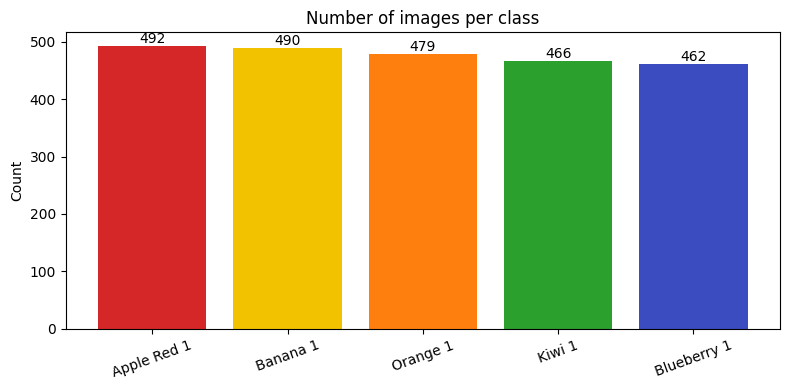

In [4]:
counts = {c: len(p) for c, p in paths.items()}

plt.figure(figsize=(8, 4))
bars = plt.bar(counts.keys(), counts.values(),
               color=["#d62728", "#f2c200", "#ff7f0e", "#2ca02c", "#3b4cc0"])
plt.bar_label(bars)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

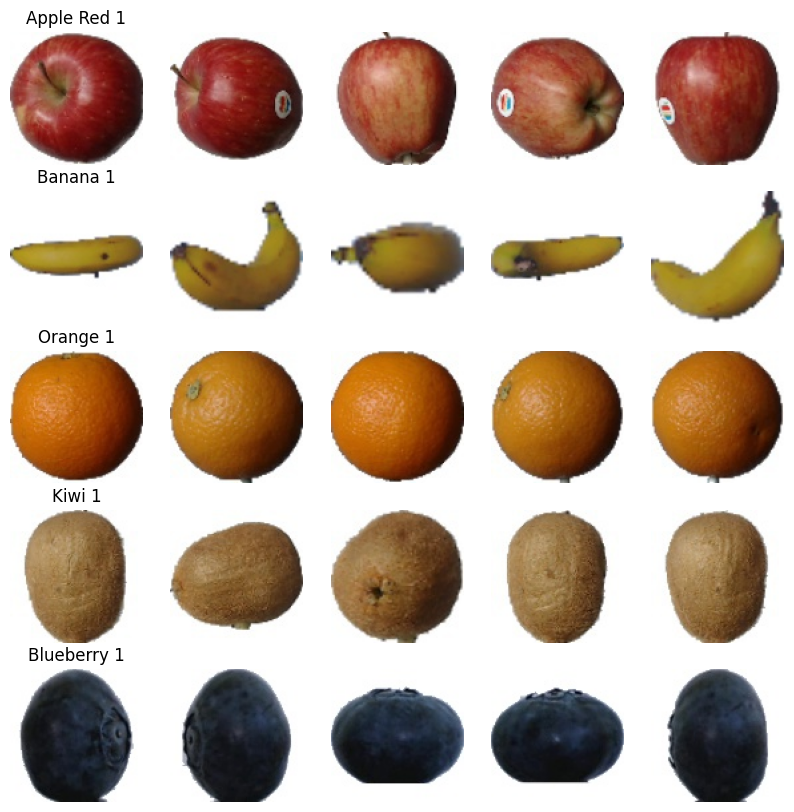

Image sizes found: {(100, 100)}


In [5]:
N = 5
fig, axes = plt.subplots(len(CLASSES), N, figsize=(2 * N, 2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(random.sample(paths[c], N)):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c)

plt.show()

sizes = set()
for c in CLASSES:
    for p in paths[c]:
        sizes.add(Image.open(p).size)

print("Image sizes found:", sizes)

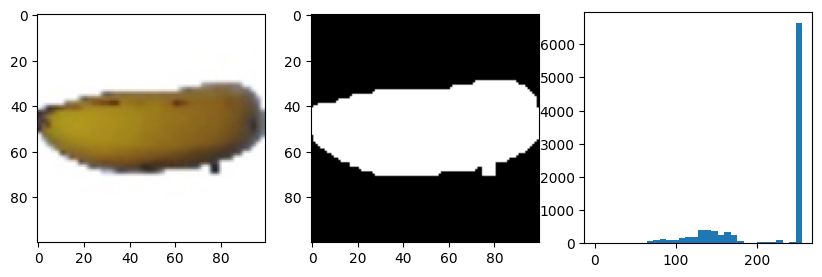

In [11]:
p = random.choice(paths["Banana 1"])
img = np.array(Image.open(p).convert("RGB"))
mask = ~(img > 240).all(axis=2)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].imshow(img)
ax[1].imshow(mask, cmap="gray")
ax[2].hist(img[..., 0].ravel(), bins=32, range=(0, 256))
plt.show()

In [7]:
def mean_hist(file_list, bins=BINS, n=150, seed=13):
    random.seed(seed)
    sample = random.sample(file_list, min(n, len(file_list)))

    all_hists = []
    for p in sample:
        img = np.array(Image.open(p).convert("RGB"))
        all_hists.append(img_hist(img, bins))

    H = np.mean(all_hists, axis=0)
    return H.reshape(3, bins)

hists = {}
for c in CLASSES:
    hists[c] = mean_hist(paths[c])


NameError: name 'BINS' is not defined

In [ ]:
centers = (np.arange(BINS) + 0.5) * (256 / BINS)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 3.2), sharey=True)
for ax, c in zip(axes, CLASSES):
    for ch, col in enumerate(["red", "green", "blue"]):
        ax.plot(centers, hists[c][ch], color=col, label=col.upper())
    ax.set_title(c)
axes[0].set_ylabel("Mean proportion")
axes[0].legend()
plt.show()

In [ ]:
from sklearn.decomposition import PCA

X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in random.sample(paths[c], min(150, len(paths[c]))):
        X.append(img_hist(np.array(Image.open(p).convert("RGB"))))
        y.append(ci)
X, y = np.array(X), np.array(y)

Z = PCA(n_components=2).fit_transform(X)

for ci, c in enumerate(CLASSES):
    plt.scatter(Z[y == ci, 0], Z[y == ci, 1], label=c)
plt.legend()
plt.show()
print("X shape:", X.shape)

In [8]:
X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in paths[c]:
        img = Image.open(p).convert("RGB").resize((100, 100))
        X.append(img_hist(np.array(img)))
        y.append(ci)

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

NameError: name 'img_hist' is not defined

In [10]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20   # test fraction of the total
VAL_SIZE = 0.20    # validation fraction of the total

# step 1: split off the test set (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=42
)

# step 2: split the rest into train and validation
# 0.20 / 0.80 = 0.25, so validation is 20% of the total
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_temp, random_state=42
)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)

# check class balance in each split
for name, labels in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, np.bincount(labels))

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [9]:

# scaler is fitted on the training set only
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

NameError: name 'X_train' is not defined